In [1]:
import sys, pandas as pd, sklearn, matplotlib
print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("Sklearn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Pandas: 2.3.3
Sklearn: 1.7.2
Matplotlib: 3.10.6


In [2]:
# Importing all the libraries we need for data analysis
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')  # hides unnecessary warnings

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
df= pd.read_csv("korba_defects.csv")

In [8]:
print("Data loaded successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])


Data loaded successfully!
Total rows: 8943
Total columns: 21


In [9]:
# Checking exact column names
# This is important because we will use these exact names later in cleaning

print("Shape of data:", df.shape)
print("\nColumn names:")
for i, col in enumerate(df.columns):
    print(i, "→", col)

Shape of data: (8943, 21)

Column names:
0 → Notif.date
1 → Notification
2 → Planner group
3 → Order
4 → Description
5 → Functional Loc.
6 → equipment
7 → Main WorkCtr
8 → Changed By
9 → User status
10 → Created On
11 → Notif. Time
12 → Created By
13 → Completion time
14 → Completn date
15 → Coding
16 → Planning plant
17 → Reported by
18 → Priority
19 → Notifictn type
20 → Plnt WorkCenter


In [10]:
# Checking data types and how many null (empty) values each column has
# This tells us which columns need cleaning

print("Column Info:")
print("-" * 50)
for col in df.columns:
    null_count = df[col].isnull().sum()
    dtype = df[col].dtype
    print(f"{col:20} | dtype: {str(dtype):10} | nulls: {null_count}")

Column Info:
--------------------------------------------------
Notif.date           | dtype: int64      | nulls: 0
Notification         | dtype: int64      | nulls: 0
Planner group        | dtype: object     | nulls: 10
Order                | dtype: float64    | nulls: 3077
Description          | dtype: object     | nulls: 0
Functional Loc.      | dtype: object     | nulls: 0
equipment            | dtype: object     | nulls: 0
Main WorkCtr         | dtype: object     | nulls: 0
Changed By           | dtype: float64    | nulls: 4
User status          | dtype: object     | nulls: 1124
Created On           | dtype: object     | nulls: 0
Notif. Time          | dtype: object     | nulls: 0
Created By           | dtype: object     | nulls: 292
Completion time      | dtype: object     | nulls: 222
Completn date        | dtype: object     | nulls: 310
Coding               | dtype: object     | nulls: 6317
Planning plant       | dtype: float64    | nulls: 292
Reported by          | dtype: obje

In [11]:
# Checking unique values in the columns we will use for ML
# This helps us understand what categories exist

cols_to_check = ['Priority', 'Notifictn type', 'User status', 'Main WorkCtr']

for col in cols_to_check:
    print(f"\n{col} — {df[col].nunique()} unique values:")
    print(df[col].value_counts().head(10))
    print("-" * 40)


Priority — 5 unique values:
Priority
Priority A              7445
Priority E- Emergent    1123
Priority C                16
Priority B                 4
Pr-C: S/D Required         3
Name: count, dtype: int64
----------------------------------------

Notifictn type — 6 unique values:
Notifictn type
M2    5943
M1    1531
OS    1056
M4      64
SA      45
M3      12
Name: count, dtype: int64
----------------------------------------

User status — 118 unique values:
User status
SCHD          4692
MNT           1613
MNS           1227
11/14/2025       7
02/14/2026       6
11/26/2025       6
12/31/2025       6
03/06/2026       6
MTP              6
11/19/2025       5
Name: count, dtype: int64
----------------------------------------

Main WorkCtr — 1 unique values:
Main WorkCtr
M400CWCT    8943
Name: count, dtype: int64
----------------------------------------


In [12]:
# Checking how many unique equipment exist
# This is our most important column

print("Total unique equipment:", df['equipment'].nunique())
print("\nTop 15 most frequent equipment:")
print(df['equipment'].value_counts().head(15))

Total unique equipment: 450

Top 15 most frequent equipment:
equipment
KORBA STATION COMMON               839
ST-2 CW CHLORINATOR STREAM NO 1    150
ST-3 CW PUMP NO.7B                  99
ST-3 CW PUMP NO.7A                  96
ST-2 TRAVELLING WATER SCREEN-2      93
ST-2 TRAVELLING WATER SCREEN-5      90
ST-2 TRAVELLING WATER SCREEN-4      85
ST-2 CW CHLORINATOR STREAM NO 2     83
ST-I TRAVELLING WATER SCREEN-1      81
ST-I TRAVELLING WATER SCREEN-5      78
H2SO4 ACID DOSING PUMP A            76
ST-2 TRAVELLING WATER SCREEN-3      75
STAGE 1 DM PLANT                    74
ST-2 TRAVELLING WATER SCREEN-1      74
ST-I TRAVELLING WATER SCREEN-4      74
Name: count, dtype: int64


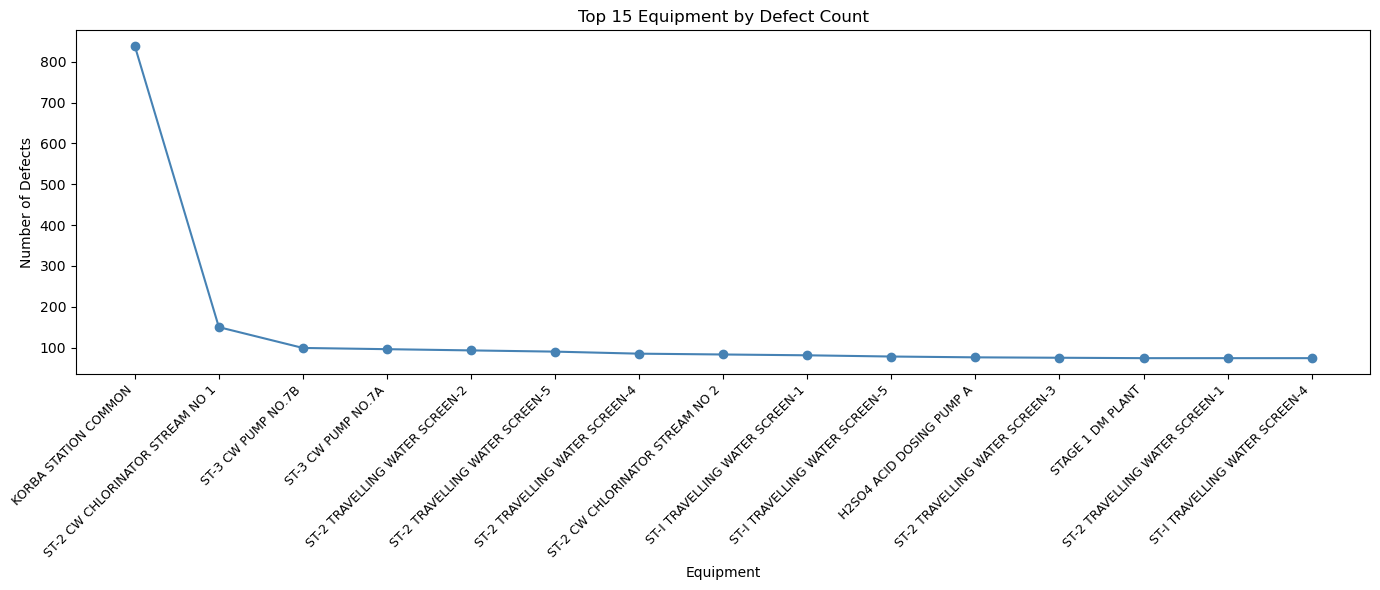

In [13]:
# Counting how many defects each equipment has
top_equipment = df['equipment'].value_counts().head(15)

# Simple line plot to see which equipment fails most
plt.figure(figsize=(14, 6))
plt.plot(top_equipment.index, top_equipment.values, marker='o', color='steelblue')

plt.title('Top 15 Equipment by Defect Count')
plt.xlabel('Equipment')
plt.ylabel('Number of Defects')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

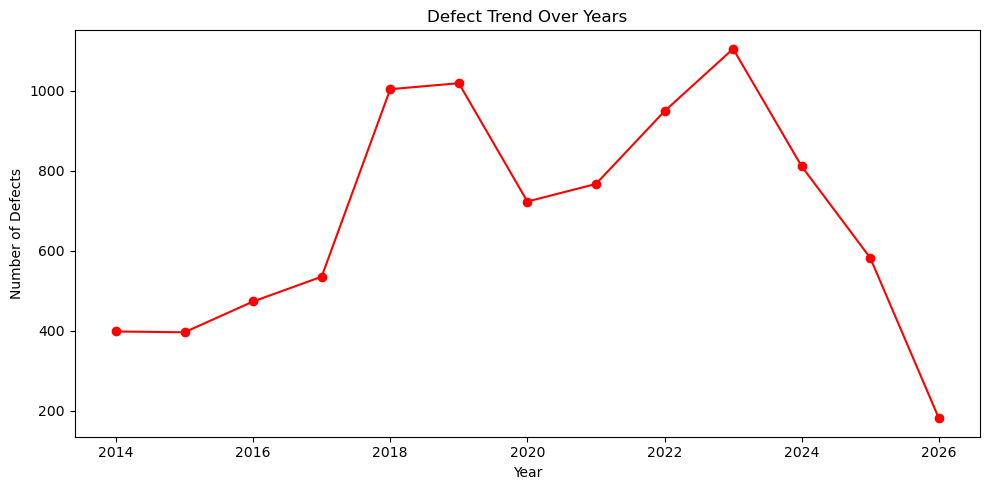

In [15]:
# Converting Notif.date to datetime so we can extract year
# Notif.date is in format 20140101 (YYYYMMDD) so we parse it accordingly
df['Notif.date'] = pd.to_datetime(df['Notif.date'], format='%Y%m%d')

# Extracting year from date
df['year'] = df['Notif.date'].dt.year

# Counting defects per year
yearly_counts = df['year'].value_counts().sort_index()

# Simple line plot to see defect trend over years
plt.figure(figsize=(10, 5))
plt.plot(yearly_counts.index, yearly_counts.values, marker='o', color='red')

plt.title('Defect Trend Over Years')
plt.xlabel('Year')
plt.ylabel('Number of Defects')
plt.tight_layout()
plt.show()

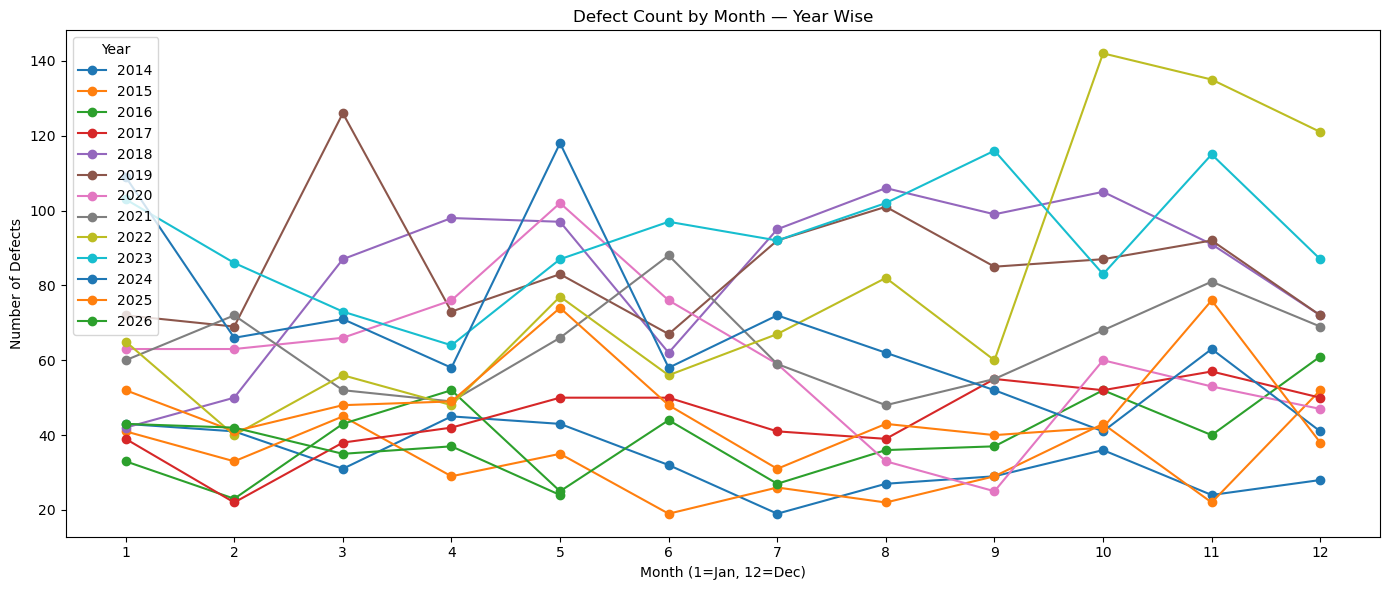

In [17]:
# Extracting month
df['month'] = df['Notif.date'].dt.month

# Plotting month wise defects separately for each year
years = sorted(df['year'].unique())

plt.figure(figsize=(14, 6))

for year in years:
    yearly_data = df[df['year'] == year]
    monthly_counts = yearly_data['month'].value_counts().sort_index()
    plt.plot(monthly_counts.index, monthly_counts.values, marker='o', label=str(year))

plt.title('Defect Count by Month — Year Wise')
plt.xlabel('Month (1=Jan, 12=Dec)')
plt.ylabel('Number of Defects')
plt.xticks(range(1, 13))
plt.legend(title='Year')
plt.tight_layout()
plt.show()

In [18]:
# Final summary of what we found in EDA
# This is like writing notes for yourself

print("=" * 50)
print("EDA SUMMARY — NTPC DEFECT DATA")
print("=" * 50)

print(f"\nTotal defect records     : {df.shape[0]}")
print(f"Total columns            : {df.shape[1]}")
print(f"Date range               : {df['Notif.date'].min().date()} to {df['Notif.date'].max().date()}")
print(f"Total unique equipment   : {df['equipment'].nunique()}")
print(f"Most defective equipment : {df['equipment'].value_counts().idxmax()}")
print(f"Most common priority     : {df['Priority'].value_counts().idxmax()}")
print(f"Most common notif type   : {df['Notifictn type'].value_counts().idxmax()}")

print("\nColumns with nulls:")
null_cols = df.isnull().sum()
null_cols = null_cols[null_cols > 0]
for col, count in null_cols.items():
    print(f"  {col:20} → {count} nulls")

print("\n" + "=" * 50)
print("EDA COMPLETE — Ready for Step 2 Cleaning!")
print("=" * 50)

EDA SUMMARY — NTPC DEFECT DATA

Total defect records     : 8943
Total columns            : 23
Date range               : 2014-01-01 to 2026-05-08
Total unique equipment   : 450
Most defective equipment : KORBA STATION COMMON
Most common priority     : Priority A
Most common notif type   : M2

Columns with nulls:
  Planner group        → 10 nulls
  Order                → 3077 nulls
  Changed By           → 4 nulls
  User status          → 1124 nulls
  Created By           → 292 nulls
  Completion time      → 222 nulls
  Completn date        → 310 nulls
  Coding               → 6317 nulls
  Planning plant       → 292 nulls
  Priority             → 352 nulls
  Notifictn type       → 292 nulls
  Plnt WorkCenter      → 292 nulls

EDA COMPLETE — Ready for Step 2 Cleaning!
